# Tối ưu và liên hệ kiến thức môn học
Slide2: gradient descent và scaling. Slide3: Bernoulli likelihood, mean log loss, gradient p-y và L1/L2. Slide5: MLE/MAP và conditional independence.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "src").exists(): root = root.parent
sys.path.insert(0, str(root / "src"))
import pandas as pd, numpy as np
from IPython.display import display, Image, Markdown
from healthcare_ml.data import load_dataset, feature_columns


In [2]:
from healthcare_ml.optimization import objective_gradient, fit_numpy
from scipy.special import expit
X=np.array([[0.],[1.]])
y=np.array([0,1])
w,b,loss=fit_numpy(X,y,rate=1,steps=40)
print("loss start/end",loss[0],loss[-1],"probabilities",expit(X@w+b))

loss start/end 0.6931471805599453 0.13388806962837807 probabilities [0.14737486 0.9028819 ]


## Công thức
`z=Xw+b`, `p=sigmoid(z)`, `J=mean(logaddexp(0,z)-y*z)+lambda*||w||²/2`. Gradient `X.T@(p-y)/n+lambda*w`; intercept không bị phạt. Cập nhật đồng thời từ cùng bước. Không đồng nhất lambda với 1/C khi quy ước loss khác nhau.

{'gradient_max_error': 6.517091033497735e-11,
 'prediction_max_difference_sklearn': 5.575777839439411e-09,
 'final_train_log_loss': 0.5166111611722191,
 'steps': 15000,
 'features': ['age', 'trestbps', 'chol', 'thalach', 'oldpeak'],
 'objective': 'unpenalized mean Bernoulli NLL',
 'sklearn_solver': 'lbfgs',
 'note': 'NumPy demo uses development fit only; not a replacement for final pipeline'}

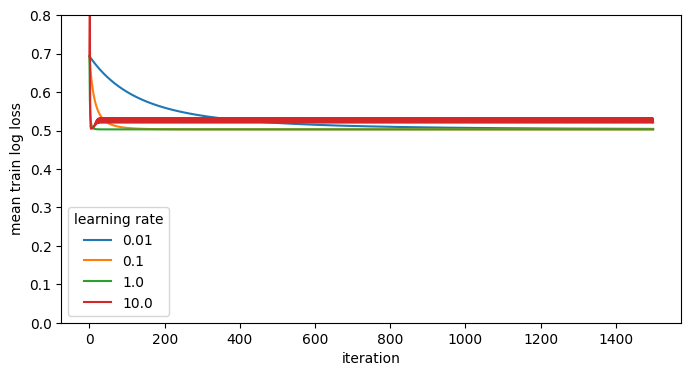

In [3]:
import json
display(json.loads((root/"artifacts/metrics/optimization.json").read_text(encoding="utf-8")))
losses=pd.read_csv(root/"artifacts/metrics/optimization_loss.csv")
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(8,4))
for rate,block in losses.groupby("rate"):
    ax.plot(block.iteration,block.train_loss,label=str(rate))
ax.set(ylim=(0, min(3,losses.train_loss.max())),xlabel="iteration",ylabel="mean train log loss")
ax.legend(title="learning rate");plt.show()

## Regularization và mô hình xác suất
L2 tương ứng Gaussian prior khi likelihood/prior và scale được đặt phù hợp; MAP là point estimate, chưa phải posterior đầy đủ. GaussianNB dùng covariance chéo, QDA dùng covariance đầy đủ có regularization. So sánh E10 cùng numerical features để tránh nhầm hiệu quả thuật toán với thêm biến.

,experiment,variant,feature_set,roc_auc,ap,brier,log_loss,train_score,nonzero,seconds
0,E02,E02_weighted_False,full,0.919262,0.924520,0.118296,0.380575,0.947326,27.8,0.026969
1,E02,E02_weighted_True,full,0.919254,0.924865,0.118745,0.381597,0.947416,27.8,0.025671
2,E06,E06_full,full,0.919262,0.924520,0.118296,0.380575,0.947326,27.8,0.025750
3,E06,E06_restricted,restricted,0.888840,0.890227,0.140648,0.438113,0.920343,20.8,0.023407
4,E08,E08_l1_C0.01,full,0.500000,0.461497,0.250000,0.693147,0.500000,0.0,0.025908
5,E08,E08_l1_C0.1,full,0.868450,0.880190,0.170466,0.522726,0.890930,6.6,0.026130
6,E08,E08_l1_C1,full,0.904613,0.916259,0.120045,0.374233,0.957289,15.8,0.027875
7,E08,E08_l1_C10,full,0.889515,0.906428,0.132661,0.491678,0.968724,21.4,0.026440
8,E08,E08_l2_C0.01,full,0.912663,0.916765,0.172080,0.530530,0.927860,27.8,0.026949
9,E08,E08_l2_C0.1,full,0.919262,0.924520,0.118296,0.380575,0.947326,27.8,0.025739


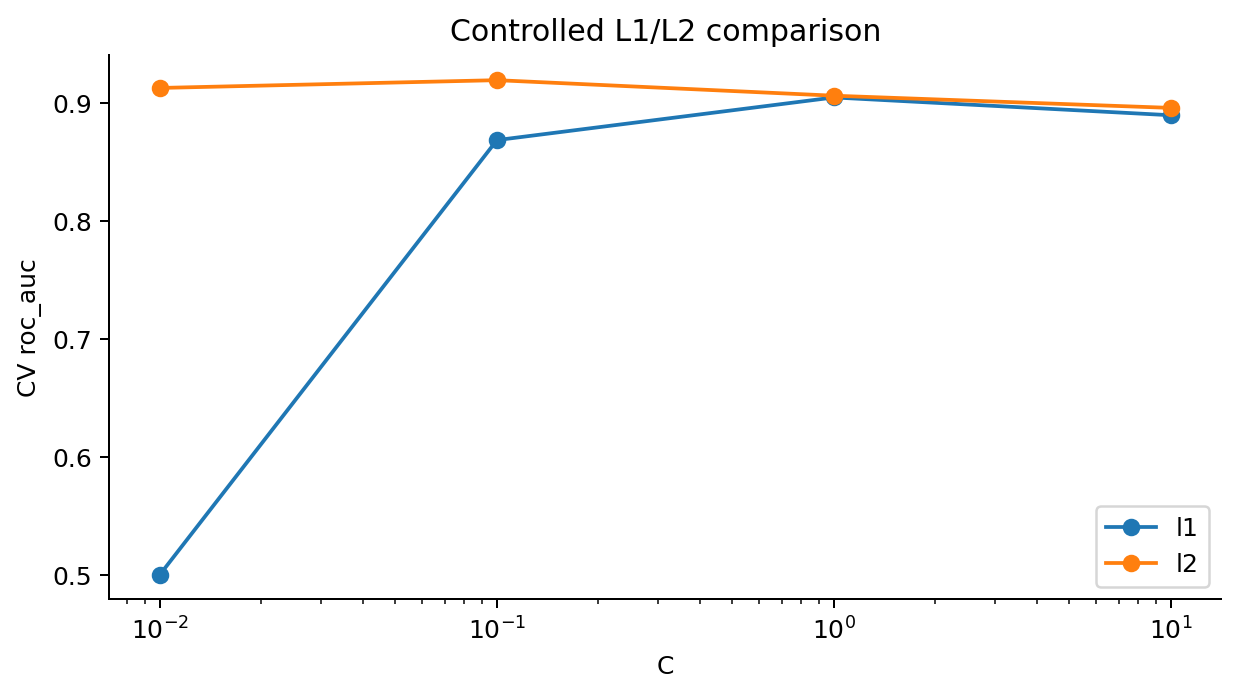

,experiment,variant,feature_set,roc_auc,ap,brier,log_loss,train_score,nonzero,seconds
0,E02,E02_weighted_False,full,0.665995,0.213326,0.095451,0.333012,0.224307,86.333333,4.717017
1,E02,E02_weighted_True,full,0.667353,0.214444,0.222491,0.640795,0.231589,199.000000,6.482810
2,E05,E05_engineered,engineered,0.664810,0.211206,0.095583,0.333486,0.218727,74.666667,6.372087
3,E05,E05_full,full,0.665995,0.213326,0.095451,0.333012,0.224307,86.333333,5.124193
4,E08,E08_l1_C0.01,full,0.652995,0.202329,0.096100,0.336053,0.204077,18.000000,3.433987
5,E08,E08_l1_C0.1,full,0.665995,0.213326,0.095451,0.333012,0.224307,86.333333,4.694781
6,E08,E08_l1_C1,full,0.655770,0.208487,0.096056,0.335733,0.258867,563.666667,6.573884
7,E08,E08_l1_C10,full,0.642000,0.200048,0.097165,0.344023,0.267273,914.666667,4.491151
8,E08,E08_l2_C0.01,full,0.667361,0.212296,0.095484,0.333072,0.224514,957.666667,3.401611
9,E08,E08_l2_C0.1,full,0.664025,0.213667,0.095456,0.333017,0.247599,957.666667,4.156027


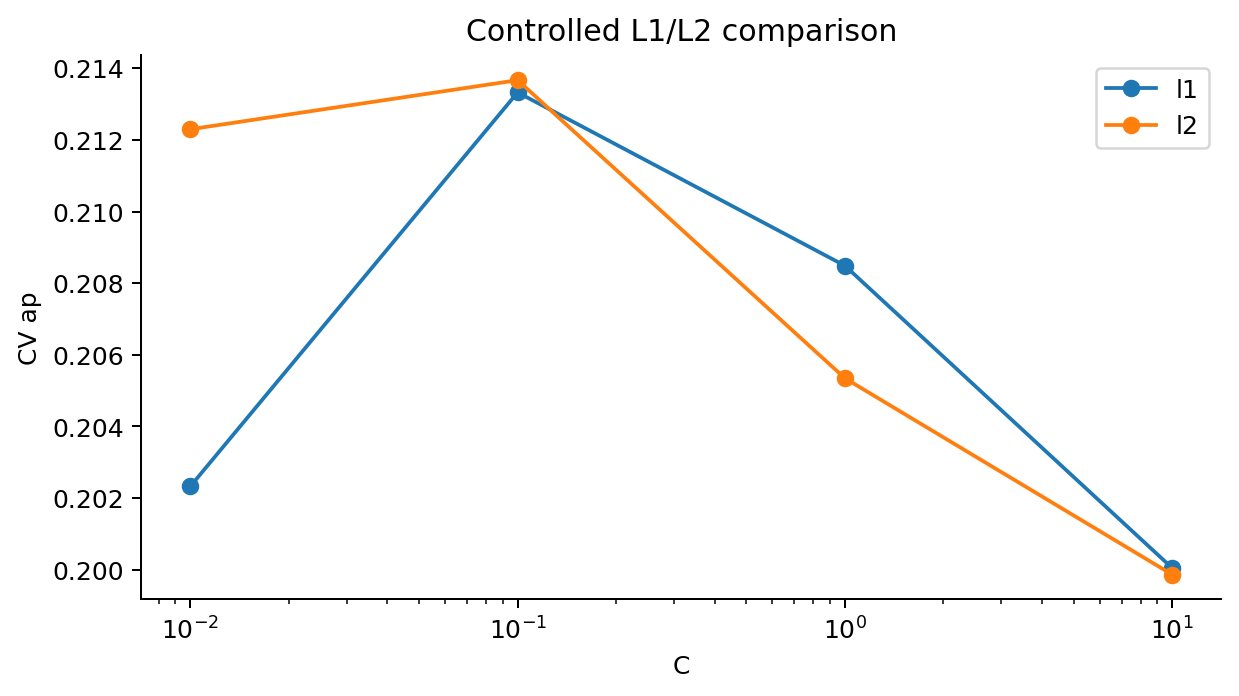

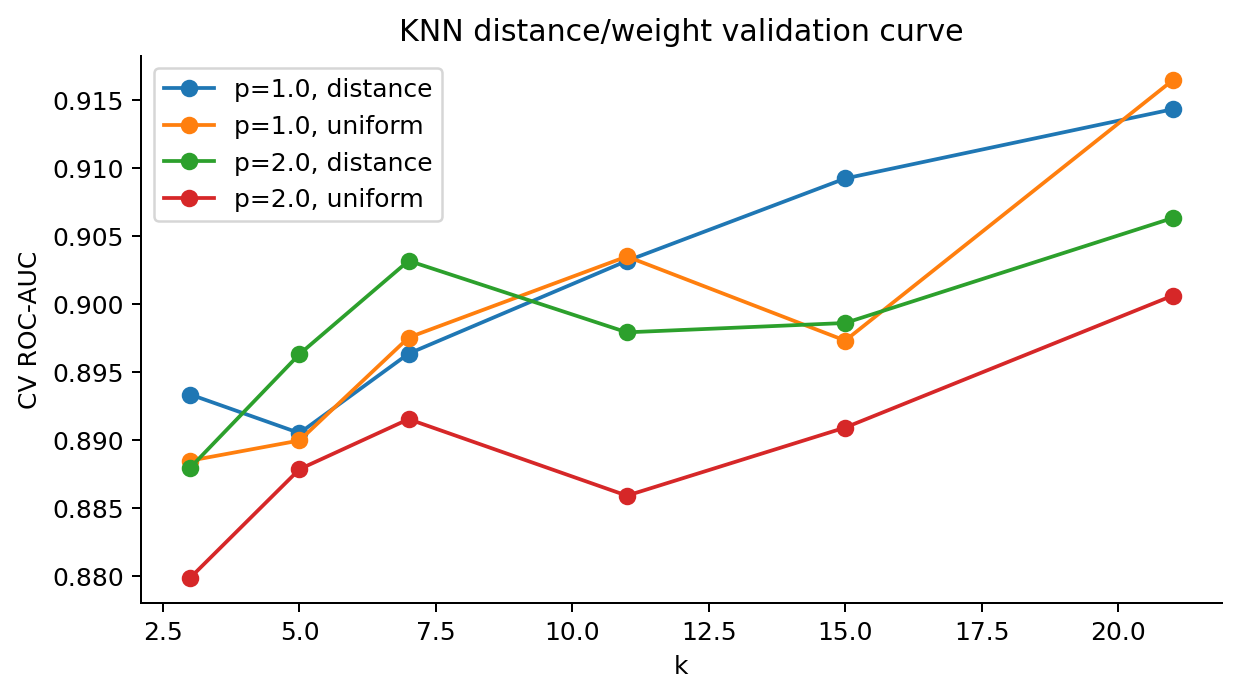

In [4]:
for name in ["heart","readmission"]:
    display(pd.read_csv(root/f"artifacts/metrics/{name}_controlled_ablations_summary.csv"))
    display(Image(filename=str(root/f"artifacts/figures/{name}_regularization.png")))
display(Image(filename=str(root/"artifacts/figures/heart_knn_controlled_curve.png")))